In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl

In [2]:
df = pd.read_csv('data/TOI519_LC_MuSCAT_z-band.csv')
df

,BJD,Flux,Err
0,2.458818e+06,1.006864,0.002557
1,2.458818e+06,1.001648,0.002534
2,2.458818e+06,0.999964,0.002608
3,2.458818e+06,1.000532,0.002580
4,2.458818e+06,1.003515,0.002646
...,...,...,...
215,2.458818e+06,0.995856,0.003269
216,2.458818e+06,1.002126,0.003383
217,2.458818e+06,0.996549,0.003573
218,2.458818e+06,0.992740,0.003558


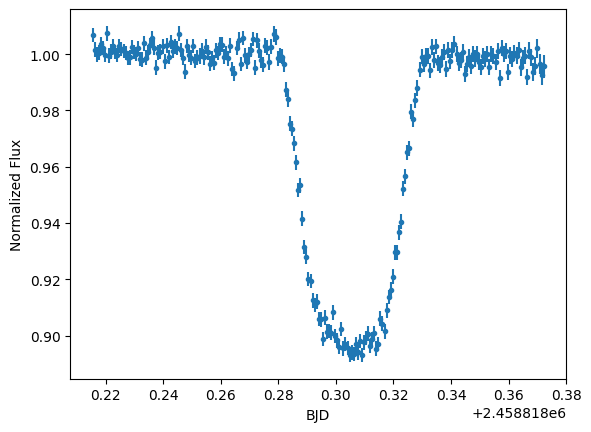

In [68]:
time = np.array(df['BJD'])
flux = np.array(df['Flux'])
err = np.array(df['Err'])

f = pl.figure()

pl.errorbar(time, flux, err, fmt='.')
pl.xlabel('BJD')
pl.ylabel('Normalized Flux')

f.savefig('output/TOI519_transit.png')

# imput parameters

Parviainen et al. (2021)

In [69]:
from uncertainties import ufloat

ra = "08:18:25.62" 
dec ="-19:39:46.05"

k_pr = ufloat(0.3, 0.0091) #Rp/Rs
a_pr = ufloat(10.11, 0.14) #a/Rs
b_pr = ufloat(0.19, 0.06)  #impact parameter, b

In [70]:
T0_pr  = ufloat(2458491.8771169, 0.)   #Transit center T0
P_pr    =  ufloat(1.2652328, 0.0000005) #Orbital Period

num = np.ceil((df['BJD'][0] - T0_pr.n)/P_pr.n) #Transit number from T0
Tc_pr = T0_pr + num * P_pr  #Predicted transit center time for this transit
Tc_pr

2458818.3071793+/-0.000129

In [71]:
from ldtk import LDPSetCreator
from ldtk.filters import sdss_z

teff, uteff = 3324,  157
feh, ufeh   = 0.0,  0.7 
logg,ulogg = 4.86877, 0.000630214

In [72]:
sc = LDPSetCreator(teff=(teff,uteff), logg=(logg,ulogg), z=(feh,ufeh), filters=[sdss_z])
ps = sc.create_profiles(nsamples=2000)
ps.resample_linear_z(100)
qd_c,qd_e = ps.coeffs_qd(do_mc=True, n_mc_samples=10000)

In [73]:
u1, u2 = list(qd_c[0])
u1e, u2e = list(qd_e[0])

# Transit Model

In [74]:
import batman

In [75]:
def transit_model(parameters, p, u1,u2, t):

    tc,a,b,k=parameters
    inc= np.arccos(b/a)*180/np.pi
    
    params = batman.TransitParams()
    params.t0 = tc                      #time of inferior conjunction
    params.per = p                     #orbital period
    params.rp = k                 #planet radius (in units of stellar radii)
    params.a = a                      #semi-major axis (in units of stellar radii)
    params.inc = inc                     #orbital inclination (in degrees)
    params.ecc = 0.                      #eccentricity
    params.w = 90.                       #longitude of periastron (in degrees)
    params.u = [u1, u2]                #limb darkening coefficients [u1, u2]
    params.limb_dark = "quadratic" 

    m = batman.TransitModel(params, np.array(t))  
    #for pallalization
    #m = batman.TransitModel(params, t, nthreads = 4)

    flux = m.light_curve(params)
    
    return flux

0.28550223244156175


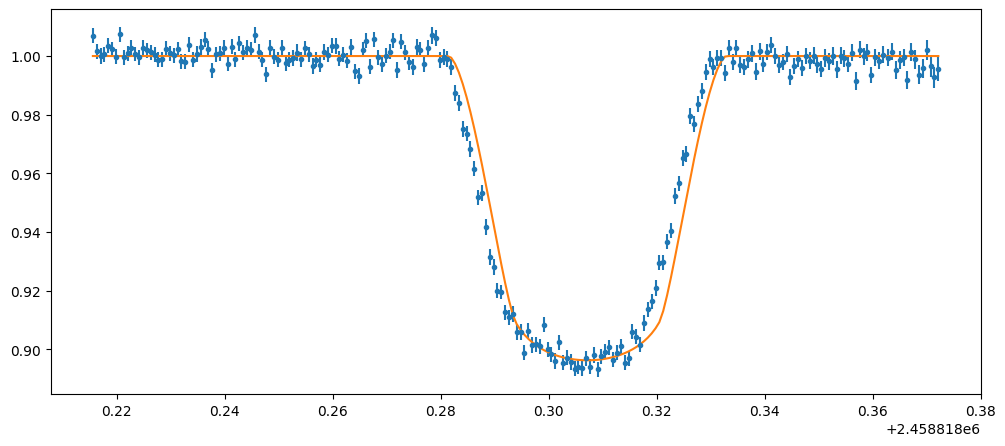

In [76]:
f=pl.figure(figsize=(12,5))

pl.errorbar(time,flux,err, fmt='.')

transit_params_pr=[Tc_pr.n,a_pr.n,b_pr.n,k_pr.n]
transit_model_pr=transit_model(transit_params_pr, P_pr.n, u1, u2, time)
pl.plot(time,transit_model_pr)
print(u1)

# Simple systematic model 


In [77]:
c0_pr = 1.
c1_pr = -0.05
c2_pr = -1

sys_params_pr = [c0_pr, c1_pr, c2_pr]

def sys_model(sys_params, t):
    c0, c1, c2 = sys_params
    return  [c0]*len(t) + c1*(t-t[0])+ c2*(t-t[0])**2

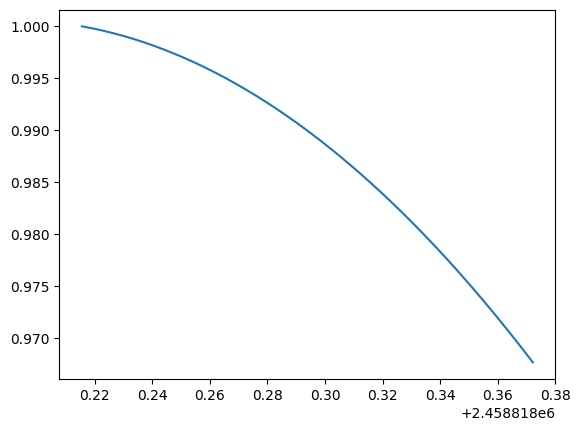

In [78]:
sys_model_pr = sys_model(sys_params_pr,time)
pl.plot(time, sys_model_pr)

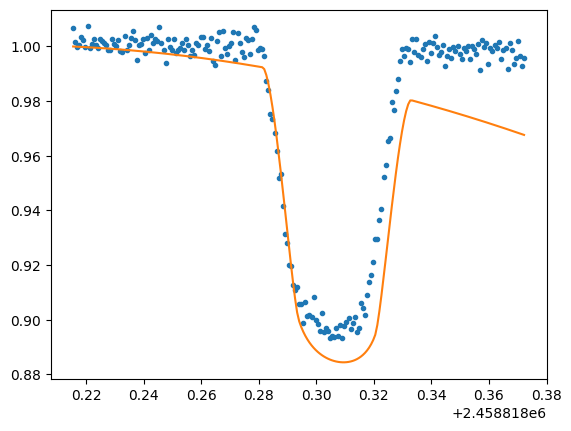

In [79]:
pl.plot(time,flux,'.')
pl.plot(time, transit_model_pr * sys_model_pr)

# preparing parameter set

In [80]:
params_full_pr = transit_params_pr + sys_params_pr
params_full_pr

[2458818.3071793, 10.11, 0.19, 0.3, 1.0, -0.05, -1]

In [147]:
params_name = 'Tc,a_Rs,b,Rp_Rs,c0,c1,c2'.split(',')
params_name

['Tc', 'a_Rs', 'b', 'Rp_Rs', 'c0', 'c1', 'c2']

# fitting

In [125]:
from scipy import stats

def loglike(flux,err,model):
    residual = flux - model
    return -0.5 * np.sum((residual/err)**2)

def logprior(params_full, time):
    
    transit_params=params_full[:4]
    Tc, a, b, k = transit_params
    
    #Uniform priors
    if not (time[0]<Tc<time[-1]):
        return -np.inf
    
    if not 0<k<1:
        return -np.inf
    
    #Normal Priors
    lp = 0
    
    lp += stats.norm.logpdf(a, loc=a_pr.n, scale=a_pr.s)
    lp += stats.norm.logpdf(b, loc=b_pr.n, scale=b_pr.s)
    
    return lp

def logprob(params_full, u1, u2, time, flux, err):  #log posterior probability

    transit_params=params_full[:4]
    Tc, a, b, k = transit_params
    sys_params=params_full[4:]
    c0, c1, c2 = sys_params
    
    tm = transit_model(transit_params, P_pr.n, u1,u2, time)
    sm = sys_model(sys_params,time)
    
    ll = loglike(flux, err, tm*sm)
    lp = logprior(params_full, time)
    
    return ll+lp

In [126]:
logprob(params_full_pr, u1, u2, time, flux, err)

-3831.566344840684

# Optimization

In [127]:
import scipy.optimize as op

def neg_logprob(params_full, u1, u2, time, flux, err):
    return -logprob(params_full, u1, u2, time, flux, err)

result = op.minimize(neg_logprob, params_full_pr, args=(u1, u2, time, flux, err),method='Powell')

In [128]:
result.x

array([ 2.45881831e+06,  1.00364730e+01,  2.72619149e-01,  2.99442093e-01,
        1.00146873e+00, -1.88655068e-02, -3.47255838e-02])

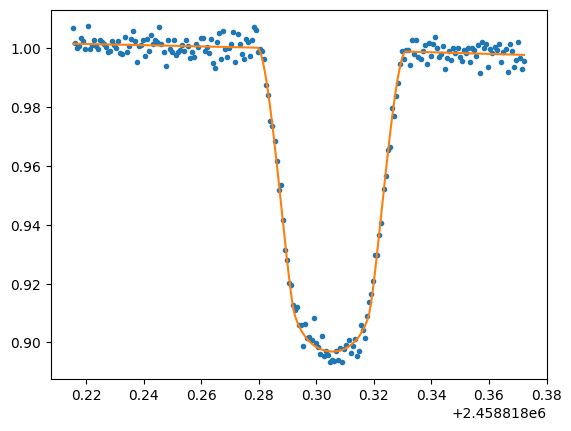

In [178]:
transit_params_opt=result.x[:4]
sys_params_opt=result.x[4:]

transit_model_opt=transit_model(transit_params_opt, P_pr.n, u1,u2, time)
sys_model_opt = sys_model(sys_params_opt,time)

pl.plot(time,flux,'.')
pl.plot(time, sys_model_opt * transit_model_opt)

# MCMC

In [133]:
import emcee

params  = result.x
ndim = len(params)
nwalkers = 64
nsteps=10000

In [164]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, logprob, args=(u1, u2, time, flux, err))

p0 = [params +  1e-5 * np.random.randn(ndim) for i in range(nwalkers)]
sampler.run_mcmc(p0, nsteps, progress=True)

100%|█████████████████████████████████████| 10000/10000 [02:26<00:00, 68.23it/s]


State([[ 2.45881831e+06  1.00902644e+01  2.56386922e-01  2.97813520e-01
   1.00190904e+00 -4.32649027e-02  1.04618030e-01]
 [ 2.45881831e+06  1.01311792e+01  2.35720749e-01  2.99063859e-01
   1.00082334e+00 -2.37747642e-03 -9.26700074e-02]
 [ 2.45881831e+06  9.99679243e+00  2.88494008e-01  3.00873934e-01
   1.00109314e+00 -8.94035932e-03 -7.46975536e-02]
 [ 2.45881831e+06  1.00530262e+01  2.46822505e-01  2.98765046e-01
   1.00214838e+00 -2.02730630e-02 -8.72434676e-02]
 [ 2.45881831e+06  1.00920793e+01  2.60411847e-01  2.98128663e-01
   1.00191806e+00 -5.05941594e-02  1.52423873e-01]
 [ 2.45881831e+06  9.97029196e+00  2.86787907e-01  2.99530281e-01
   1.00245617e+00 -3.71239571e-02  3.71554581e-02]
 [ 2.45881831e+06  1.01071880e+01  2.35191143e-01  2.96724991e-01
   1.00199827e+00 -4.73988266e-02  1.83241892e-01]
 [ 2.45881831e+06  9.99683587e+00  2.87979282e-01  2.98534915e-01
   1.00273401e+00 -3.97191990e-02  3.17548053e-02]
 [ 2.45881831e+06  1.00731711e+01  2.71537870e-01  2.97227

In [165]:
#convergence check
sampler.acceptance_fraction

array([0.4826, 0.4822, 0.4989, 0.4834, 0.4799, 0.488 , 0.4868, 0.4866,
       0.4835, 0.4933, 0.4883, 0.4859, 0.4858, 0.4792, 0.4742, 0.4805,
       0.4832, 0.479 , 0.4799, 0.4891, 0.4865, 0.4817, 0.4895, 0.474 ,
       0.4705, 0.4919, 0.4882, 0.4815, 0.4945, 0.4812, 0.4938, 0.485 ,
       0.485 , 0.4909, 0.485 , 0.4936, 0.493 , 0.4878, 0.4834, 0.487 ,
       0.4803, 0.491 , 0.4855, 0.4859, 0.4981, 0.4814, 0.4921, 0.4841,
       0.4881, 0.4811, 0.4862, 0.4876, 0.4892, 0.4861, 0.4888, 0.4893,
       0.4794, 0.4893, 0.4736, 0.4852, 0.4864, 0.4845, 0.4868, 0.4903])

In [166]:
tau = sampler.get_autocorr_time()
tau

array([79.55378615, 78.33197211, 77.57732928, 73.06602268, 73.88095918,
       76.33255569, 75.97906544])

In [167]:
samples = sampler.get_chain(discard=0, thin=1)

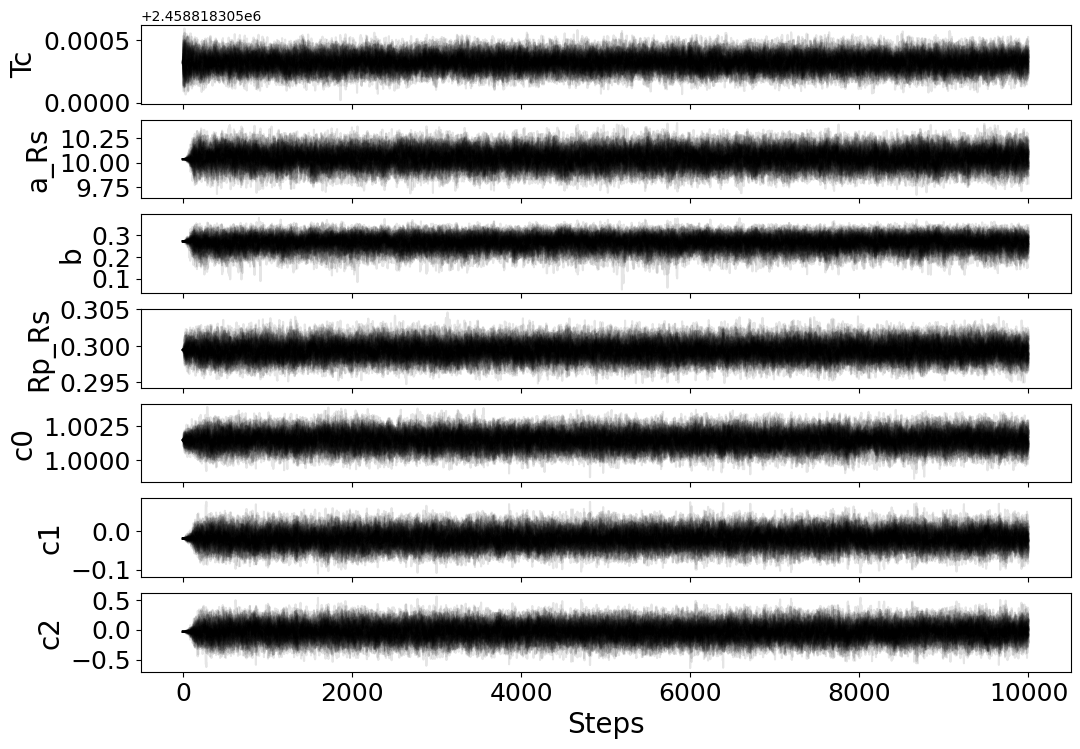

In [168]:
fig, ax = pl.subplots(ndim, 1, figsize=(10*1.2,ndim*1.2))

for i in range(ndim):
    ax[i].plot(samples[:, :, i], color='k', alpha=0.1)
    
    if i==(ndim-1):
        pl.setp(ax[i].get_xticklabels(), visible=True, fontsize=18)
        ax[i].set_xlabel('Steps', fontsize=20)
    else:
        pl.setp(ax[i].get_xticklabels(), visible=False)
    
    pl.setp(ax[i].get_yticklabels(), fontsize=18)
    ax[i].set_ylabel(params_name[i],fontsize=20)

In [172]:
flat_samples = sampler.get_chain(discard=5000, thin=10, flat=True)

In [173]:
best_params=[]
best_params_err = []

for i in range(ndim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)

    best_params.append(mcmc[1])
    best_params_err.append(np.mean(q))

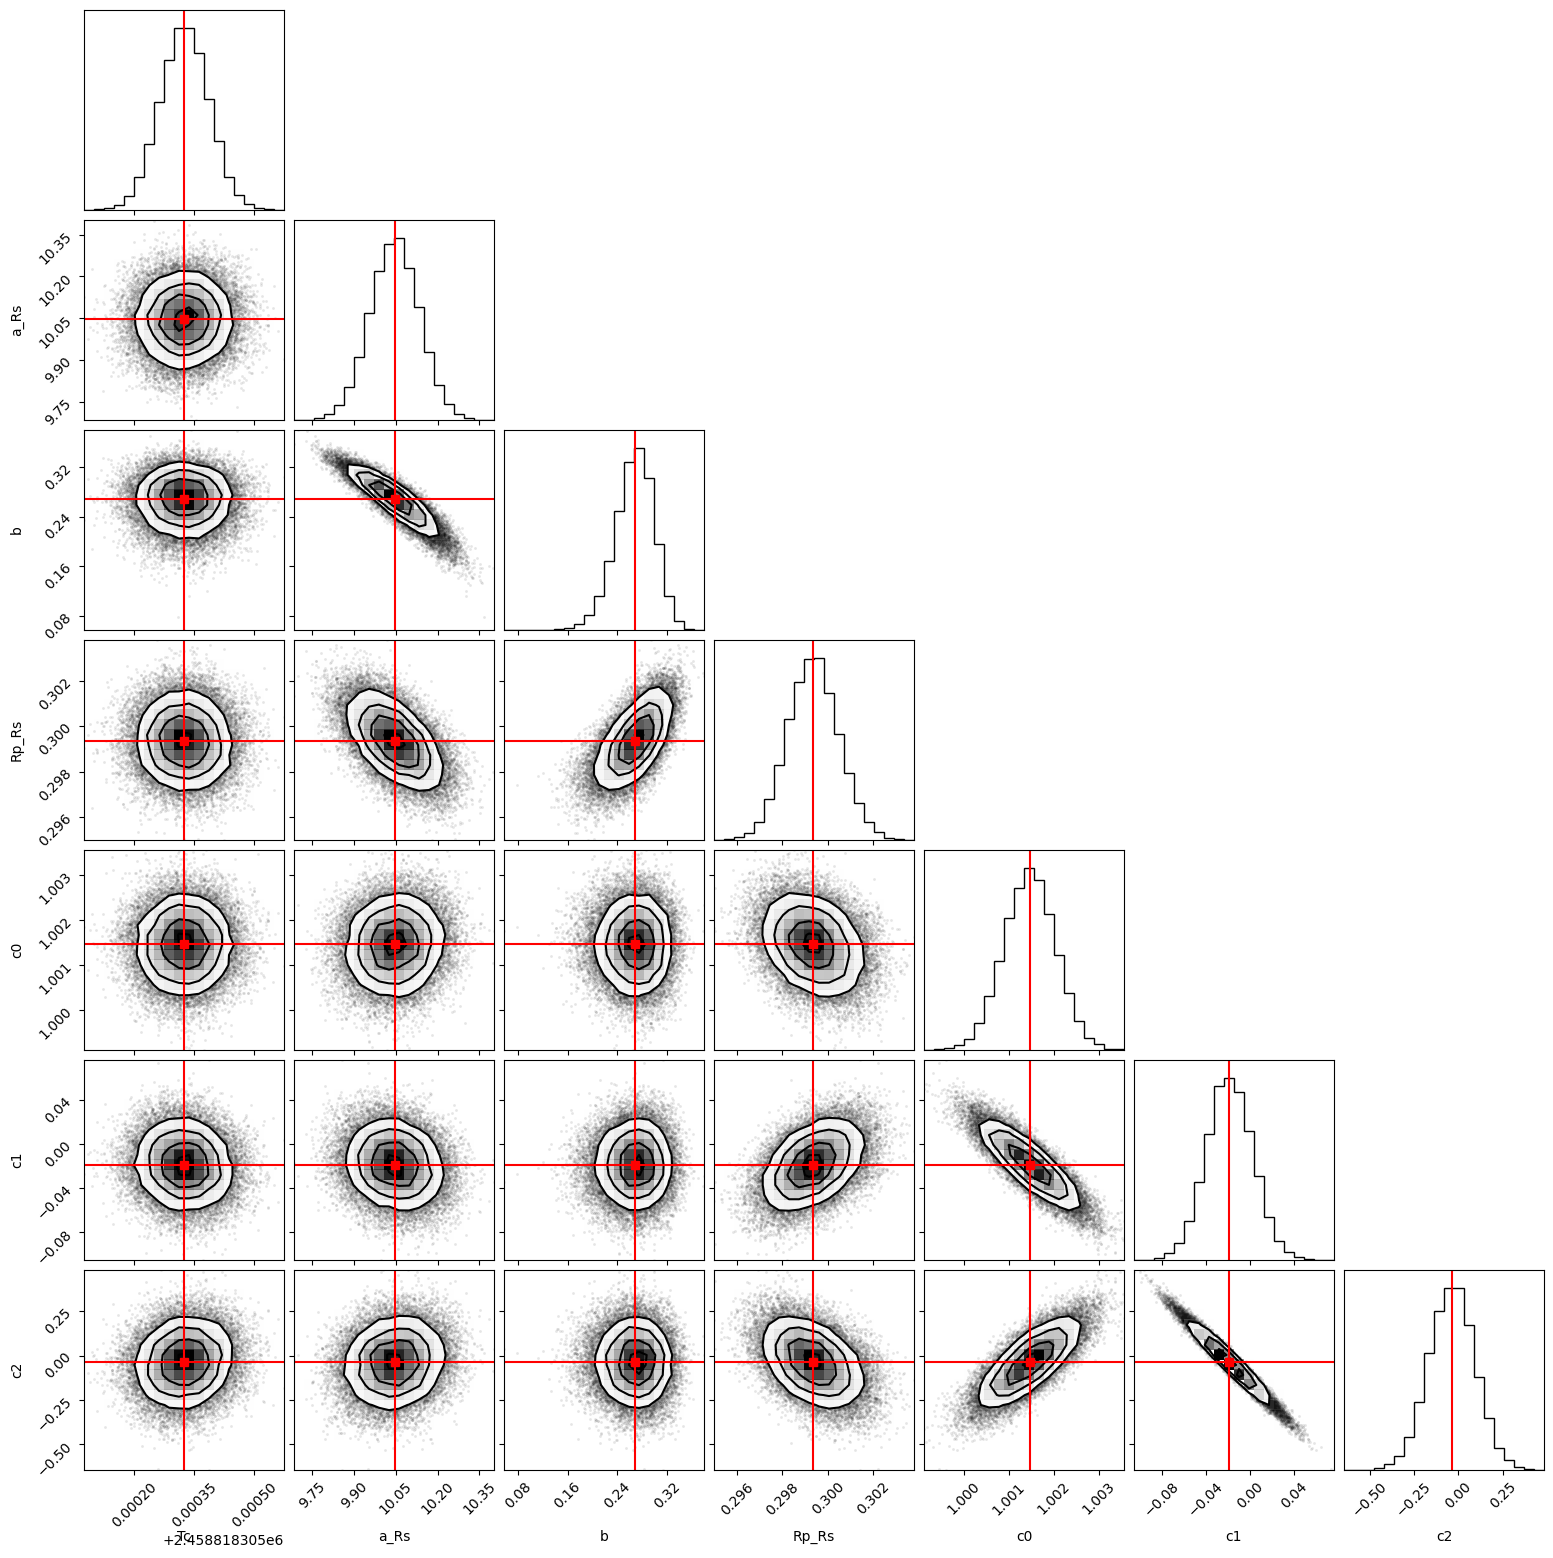

In [175]:
import corner

indx=18
figure = corner.corner(flat_samples, fontsize=10, labels=params_name)
value2 = best_params

# Extract the axes
axes = np.array(figure.axes).reshape((ndim, ndim))

# Loop over the diagonal
for i in range(ndim):
    ax = axes[i, i]
    ax.axvline(value2[i], color="r")

# Loop over the histograms
for yi in range(ndim):
    for xi in range(yi):
        ax = axes[yi, xi]
        ax.axvline(value2[xi], color="r")
        ax.axhline(value2[yi], color="r")
        ax.plot(value2[xi], value2[yi], "sr")

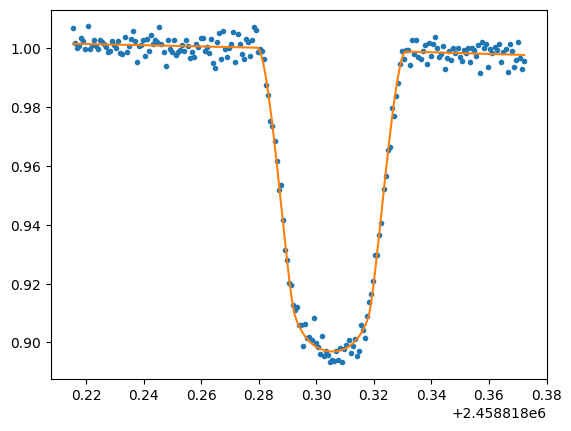

In [177]:
transit_params_best=best_params[:4]
sys_params_best=best_params[4:]

transit_model_best=transit_model(transit_params_best, P_pr.n, u1, u2, time)
sys_model_best = sys_model(sys_params_best,time)

pl.plot(time,flux,'.')
pl.plot(time, sys_model_best * transit_model_best)